# Accelerating and decelerating loads

The same total melt of Northern Hemisphere ice, delivered over 20 years in two ways. With $s=t/T$ and $T=20$ yr:
- **accelerating:** $a(t)=s^2$. The melt rate starts at zero and grows, then stops abruptly at $t=T$;
- **decelerating:** $a(t)=s(2-s)$. The melt rate starts at its largest and falls to zero at $t=T$.

The static (AA24) pole follows $a(t)\,\boldsymbol\omega_s$. The dynamic pole lags behind it. For a linear trend, the note
gives a constant offset at right angles to the drift, equal to the static drift over
$\tau=1/\sigma'_{\rm CW}+1/\Omega$. When the rate changes slowly, the offset should follow the instantaneous rate:
$|\dot{\boldsymbol\omega}_s|\,\tau$. It should therefore grow for the accelerating load and shrink for the decelerating one.
Wherever the rate changes abruptly, the offset cannot follow, and a free wobble of the size of the jump in offset is left
behind. That happens at the end of the accelerating load and at the start of the decelerating one. The Earth here has a
fluid core and damping, so each free wobble then decays, with e-folding time $QT'_{\rm CW}/\pi$ (about 37 yr for $Q=100$).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import solver_dynamic as sd
import examples_dynamic_helper as eh

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Parameters, Earth model and loads

In [2]:
#=======================================================================
# Parameters
#=======================================================================

lmax = 32
rtol = 1e-10
year_days = 365.25

# Quality factor of the free wobble (None for no damping)
quality_factor = sd.DEFAULT_QUALITY_FACTOR

# Fraction of Northern Hemisphere ice melted in total
nh_fraction = 1e-3

# Duration of the melt, and of the run after it ends (years)
melt_years = 20.0
after_years = 6.0

# Time steps (days); the free-wobble run measures the Chandler period
dt_days = 30.0
dt_free_days = 14.0
free_years = 3.0

In [3]:
#=======================================================================
# Earth model, constants and the static response
#=======================================================================

state = sd.make_state(lmax)
model = state.model
constants = sd.rotation_constants(model)

day = float(sd.days_to_model_time(1.0, constants))
year = year_days * day
length_scale_mm = constants["length_scale"] * 1e3

nh_load = state.northern_hemisphere_load(fraction=nh_fraction)
static_nh = sd.equilibrium_rotation(state, constants, nh_load, rtol=1e-12)
print(f"static pole shift for the full melt: {sd.omega_to_mas(static_nh['omega'], constants)} mas")

static pole shift for the full melt: [ 22.95131696 -17.20676661] mas


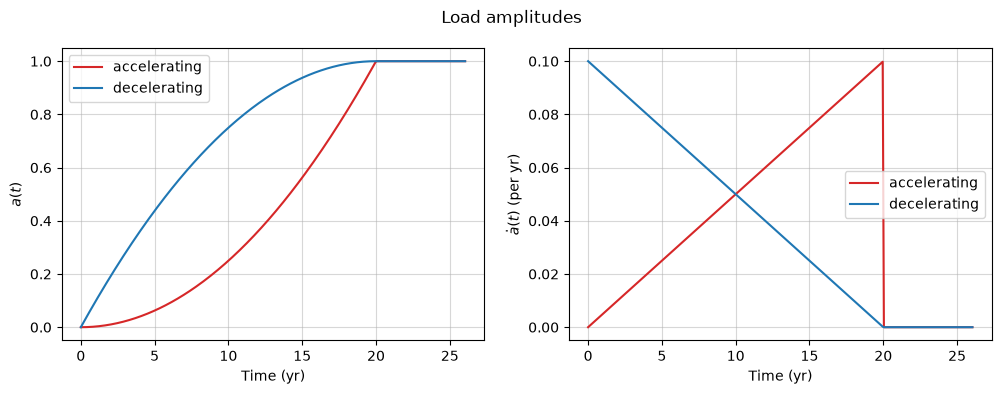

In [4]:
#=======================================================================
# The two amplitudes, built from a linear ramp s = t / T
#=======================================================================

s = sd.LinearRamp(melt_years * year)
accelerating = s * s
decelerating = s * (2 - s)

t = np.arange(0.0, (melt_years + after_years) * year + 0.5 * dt_days * day, dt_days * day)
t_years = sd.model_time_to_days(t, constants) / year_days

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for amplitude, label, colour in [(accelerating, "accelerating", "tab:red"), (decelerating, "decelerating", "tab:blue")]:
    axes[0].plot(t_years, [amplitude.value(ti) for ti in t], color=colour, label=label)
    axes[1].plot(t_years, [amplitude.rate(ti) * year for ti in t], color=colour, label=label)
axes[0].set_ylabel(r"$a(t)$")
axes[1].set_ylabel(r"$\dot a(t)$ (per yr)")
for ax in axes:
    ax.set_xlabel("Time (yr)")
    ax.legend()
    ax.grid(True, alpha=0.5)
fig.suptitle("Load amplitudes")
plt.show()

## 1. The Chandler period, and the lag time $\tau$

A short free-wobble run with the ocean gives $\sigma'_{\rm CW}$ at this resolution, and hence $\tau=1/\sigma'_{\rm CW}+1/\Omega$.

In [5]:
#=======================================================================
# Free wobble, for the Chandler period
#=======================================================================

no_load = sd.SeparableLoad([(model.zero_grid(), 0.0)])
rhs_free = sd.forward_rhs(state, constants, no_load, quality_factor=quality_factor, rtol=rtol)
t_free = np.arange(0.0, free_years * year, dt_free_days * day)
omega_free = sd.integrate(rhs_free, np.array([1e-7, 0.0]), t_free)

t_cw_days = eh.wobble_period_days(sd.model_time_to_days(t_free, constants), omega_free)
omega_per_day = constants["omega"] * day
lag_days = t_cw_days / (2 * np.pi) + 1 / omega_per_day
e_fold_days = np.inf if quality_factor is None else quality_factor * t_cw_days / np.pi
print(f"T_CW = {t_cw_days:.2f} d;  lag time tau = 1/sigma'_CW + 1/Omega = {lag_days:.2f} d;  "
      f"e-folding time of the wobble {e_fold_days / year_days:.1f} yr")

T_CW = 422.78 d;  lag time tau = 1/sigma'_CW + 1/Omega = 67.45 d;  e-folding time of the wobble 36.8 yr


## 2. The two runs, from rest

In [6]:
#=======================================================================
# Accelerating and decelerating melt, with the ocean
#=======================================================================

runs = {}
for label, amplitude in [("accelerating", accelerating), ("decelerating", decelerating)]:
    load = sd.SeparableLoad([(nh_load, amplitude)])
    rhs = sd.forward_rhs(state, constants, load, quality_factor=quality_factor, rtol=rtol)

    start_time = time.time()
    omega = sd.integrate(rhs, np.zeros(2), t)
    print(f"{label}: run took {time.time() - start_time:.1f} s")

    a = np.array([amplitude.value(ti) for ti in t])
    a_dot = np.array([amplitude.rate(ti) for ti in t])
    runs[label] = {
        "load": load,
        "omega": omega,
        "omega_static": np.outer(a, static_nh["omega"]),
        "a_dot": a_dot,
    }

accelerating: run took 59.5 s


decelerating: run took 62.4 s


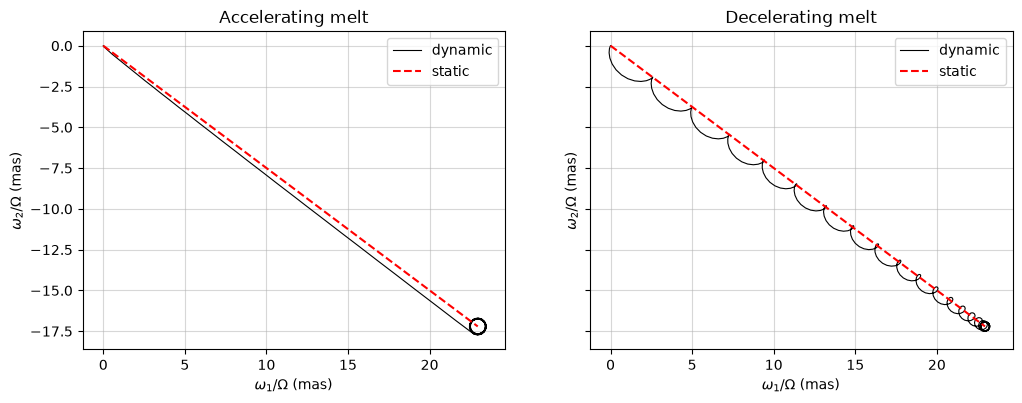

In [7]:
#=======================================================================
# Polar paths: dynamic and static
#=======================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (label, run) in zip(axes, runs.items()):
    pole = sd.omega_to_mas(run["omega"], constants)
    pole_static = sd.omega_to_mas(run["omega_static"], constants)
    ax.plot(pole[:, 0], pole[:, 1], "k", lw=0.8, label="dynamic")
    ax.plot(pole_static[:, 0], pole_static[:, 1], "r--", label="static")
    ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
    ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
    ax.set_aspect("equal")
    ax.set_title(f"{label.capitalize()} melt")
    ax.legend()
    ax.grid(True, alpha=0.5)
plt.show()

## 3. The lag behind the static pole

The deviation $|\boldsymbol\omega-\boldsymbol\omega_{\rm static}|$ is compared with the predicted offset $|\dot{\boldsymbol\omega}_s|\,\tau=|\dot a|\,|\boldsymbol\omega_s|\,\tau$.
Where a free wobble has been excited, it adds to the offset as a vector, so the deviation swings between their sum and their
difference. For the decelerating melt the wobble comes from the abrupt start, and decays during the melt while the offset
shrinks. For the accelerating melt it starts at the end of the melt.

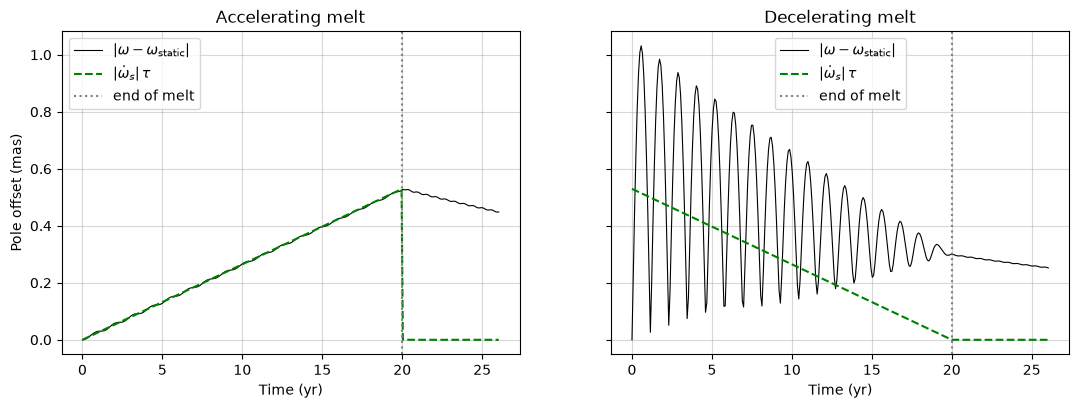

accelerating: free wobble in the year after the melt 0.523 mas; predicted 0.523 mas (excited 0.5 yr earlier at 0.530 mas)
decelerating: free wobble in the year after the melt 0.295 mas; predicted 0.304 mas (excited 20.5 yr earlier at 0.530 mas)


In [8]:
#=======================================================================
# Deviation from the static pole, against the predicted offset
#=======================================================================

static_mas = np.linalg.norm(sd.omega_to_mas(static_nh["omega"], constants))
lag = lag_days * day

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (label, run) in zip(axes, runs.items()):
    deviation_mas = np.linalg.norm(sd.omega_to_mas(run["omega"] - run["omega_static"], constants), axis=1)
    offset_mas = np.abs(run["a_dot"]) * static_mas * lag
    ax.plot(t_years, deviation_mas, "k", lw=0.8, label=r"$|\omega - \omega_{\rm static}|$")
    ax.plot(t_years, offset_mas, "g--", label=r"$|\dot\omega_s|\,\tau$")
    ax.axvline(melt_years, color="grey", ls=":", label="end of melt")
    ax.set_xlabel("Time (yr)")
    ax.set_title(f"{label.capitalize()} melt")
    ax.legend()
    ax.grid(True, alpha=0.5)
axes[0].set_ylabel("Pole offset (mas)")
plt.show()

# Free wobble in the first year after the melt. Both are excited by a jump of 2 / T in the rate,
# so both start with amplitude (2 / T) |omega_s| tau, but they were excited at different times
initial_wobble_mas = 2 / melt_years * static_mas * lag_days / year_days
first_year = (t_years > melt_years) & (t_years <= melt_years + 1)
for label, years_since_excited in [("accelerating", 0.5), ("decelerating", melt_years + 0.5)]:
    run = runs[label]
    wobble_mas = np.linalg.norm(sd.omega_to_mas(run["omega"][first_year] - run["omega_static"][first_year], constants), axis=1)
    predicted_mas = initial_wobble_mas * np.exp(-years_since_excited * year_days / e_fold_days)
    print(f"{label}: free wobble in the year after the melt {wobble_mas.mean():.3f} mas; "
          f"predicted {predicted_mas:.3f} mas (excited {years_since_excited:.1f} yr earlier at {initial_wobble_mas:.3f} mas)")

## 4. Sea level: dynamic minus static, at the end of the melt

The difference is the sea-level signature of the lag and of any free wobble, at $t=T$.

accelerating: max |dynamic - static| = 0.025 mm, max |static| = 56.4 mm
decelerating: max |dynamic - static| = 0.013 mm, max |static| = 56.4 mm


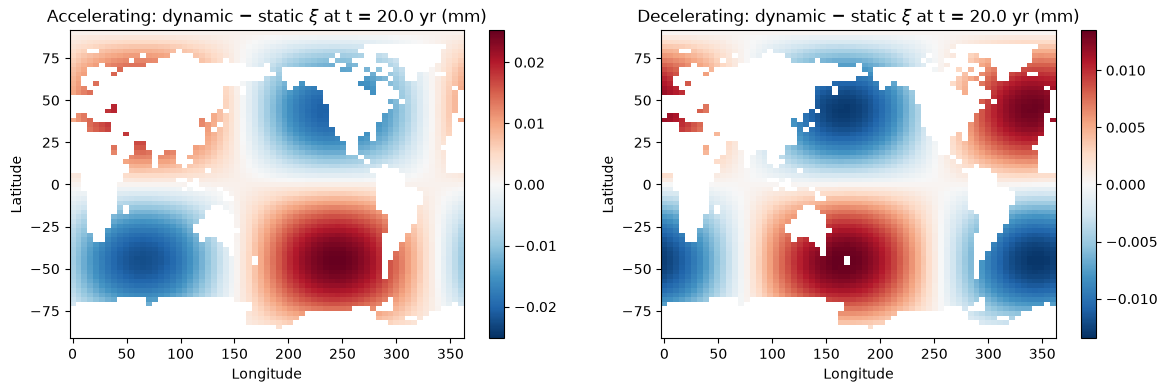

In [9]:
#=======================================================================
# Dynamic minus static sea level at t = T (mm)
#=======================================================================

n_end = np.argmin(np.abs(t_years - melt_years))
ocean_mask = np.where(state.ocean_function.data > 0, 1.0, np.nan)
static_sea_level = static_nh["sea_level"].data

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (label, run) in zip(axes, runs.items()):
    amplitude = run["load"].terms[0][1]
    slc_dynamic = sd.sea_level(state, constants, run["load"], t[n_end], run["omega"][n_end], rtol=rtol).data
    slc_static = amplitude.value(t[n_end]) * static_sea_level
    difference_mm = (slc_dynamic - slc_static) * length_scale_mm * ocean_mask
    image = ax.pcolormesh(state.lons(), state.lats(), difference_mm, cmap="RdBu_r", shading="auto")
    limit = np.nanmax(np.abs(difference_mm))
    image.set_clim(-limit, limit)
    fig.colorbar(image, ax=ax)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(rf"{label.capitalize()}: dynamic $-$ static $\xi$ at t = {t_years[n_end]:.1f} yr (mm)")
    print(f"{label}: max |dynamic - static| = {limit:.3f} mm, "
          f"max |static| = {np.nanmax(np.abs(slc_static * length_scale_mm * ocean_mask)):.1f} mm")
plt.show()